##  Установка и импорт библиотек

In [32]:
%pip install pandas
%pip install numpy
%pip install matplotlib
%pip install pillow
%pip install torch
%pip install torchvision
%pip install scikit-learn
%pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 10.7 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.3/20.3 MB 8.8 MB/s  0:00:02m0:00:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [scikit-learn] [scikit-learn]
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [21]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split
import torch.optim as optim
from sklearn.metrics import f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
import time
from IPython.display import clear_output


## Анализ и подготовка данных

Изучим представленный датасет (https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000/data)


Расшифровка обозначений:
1. **MEL**:  Уверенность в диагнозе «меланома» <br>
<br>
2. **NV**:   Уверенность в диагнозе «меланоцитарный невус» <br>
<br>
3. **BCC**:  Уверенность в диагнозе «базальноклеточная карцинома» <br>
<br>
4. **AKIEC** «Актинический кератоз / Болезнь Боуэна (внутриэпителиальная карцинома)» — уверенность в диагнозе. <br>
<br>
5. **BKL** : "Доброкачественный кератоз (солнечная лентиго / себорейный кератоз / кератоз, похожий на красный плоский лишай)" — уверенность в диагнозе<br>
<br>
6. **DF** : Уверенность в диагнозе «Дерматофиброма» <br>
<br>
7. **VASC**: Уверенность в диагнозе «сосудистое поражение» <br>


In [22]:
df = pd.read_csv('data/HAM10000_metadata.csv')
print(f"Total samples: {len(df)}")
print(f"Columns: {list(df.columns)}")
df.head()

Total samples: 10015
Columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


Посмотрим на изображения (все изображения имеют размер 600x450 пикселей и представляют собой цветные изображения опухолей кожи)

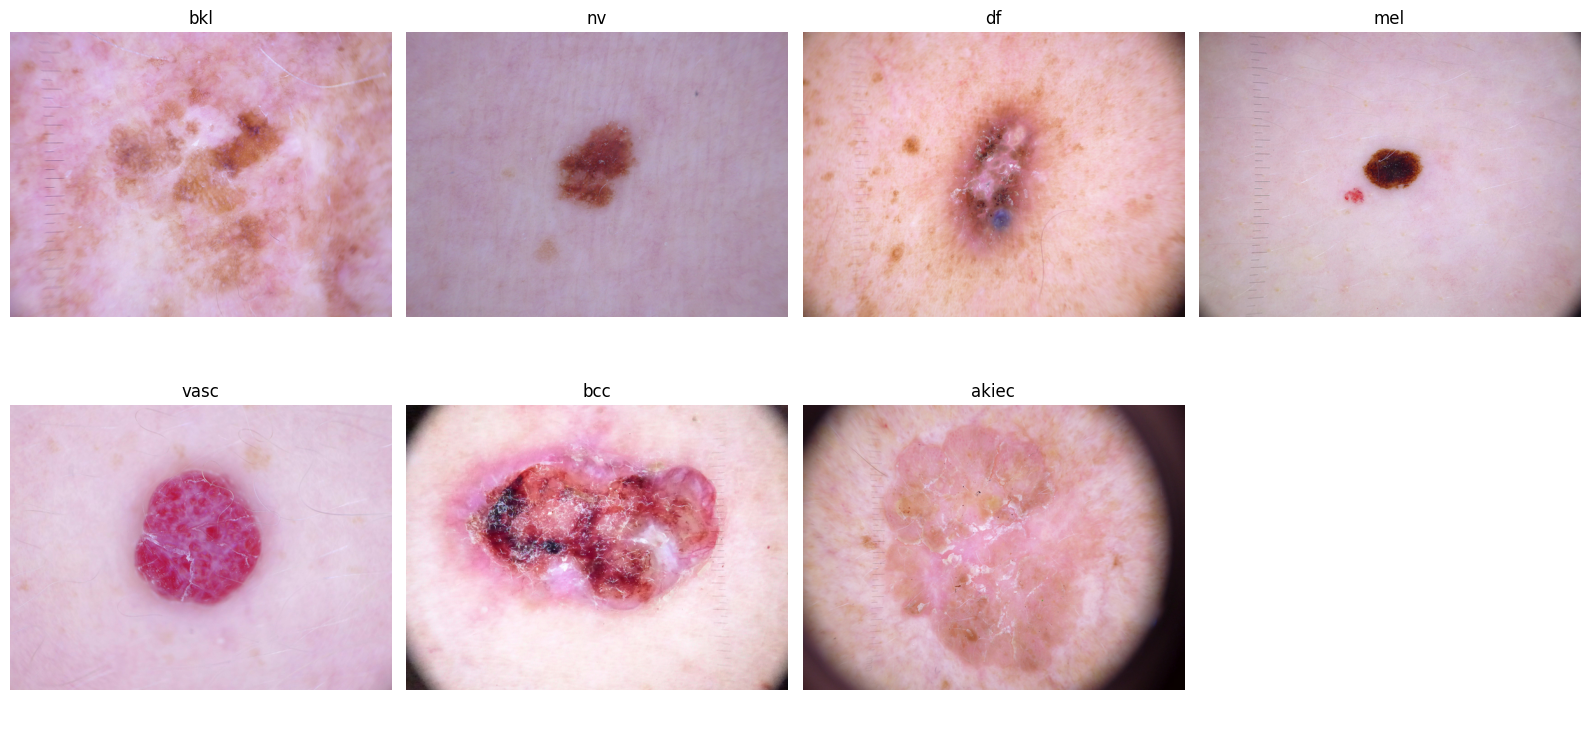

In [23]:

def showimagedata():
    data_dir = Path('data')
    img_dirs = sorted([d for d in data_dir.iterdir() if d.is_dir() and 'images' in d.name])

    classes = df['dx'].unique()
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()

    for i, cls in enumerate(classes):
        sample_id = df[df['dx'] == cls]['image_id'].iloc[0]
        
        matching_files = []
        for folder in img_dirs:
            found = [f for f in folder.iterdir() if f.stem.lower() == str(sample_id).lower()]
            if found:
                matching_files.extend(found)
                break
        
        if matching_files:
            img_path = matching_files[0]
            img = Image.open(img_path)
            axes[i].imshow(img)
            axes[i].set_title(cls)
            axes[i].axis('off')
            
    for j in range(len(classes), len(axes)):
        axes[j].axis('off')
        
    plt.tight_layout()
    plt.show()
showimagedata()

Посмотрим на распределение элементов внутри каждого класса

In [24]:
class_counts = df['dx'].value_counts().sort_index()
print("Class distribution:")
for cls, count in class_counts.items():
    print(f"{cls}: {count} ({count/len(df)*100:.1f}%)")

Class distribution:
akiec: 327 (3.3%)
bcc: 514 (5.1%)
bkl: 1099 (11.0%)
df: 115 (1.1%)
mel: 1113 (11.1%)
nv: 6705 (66.9%)
vasc: 142 (1.4%)


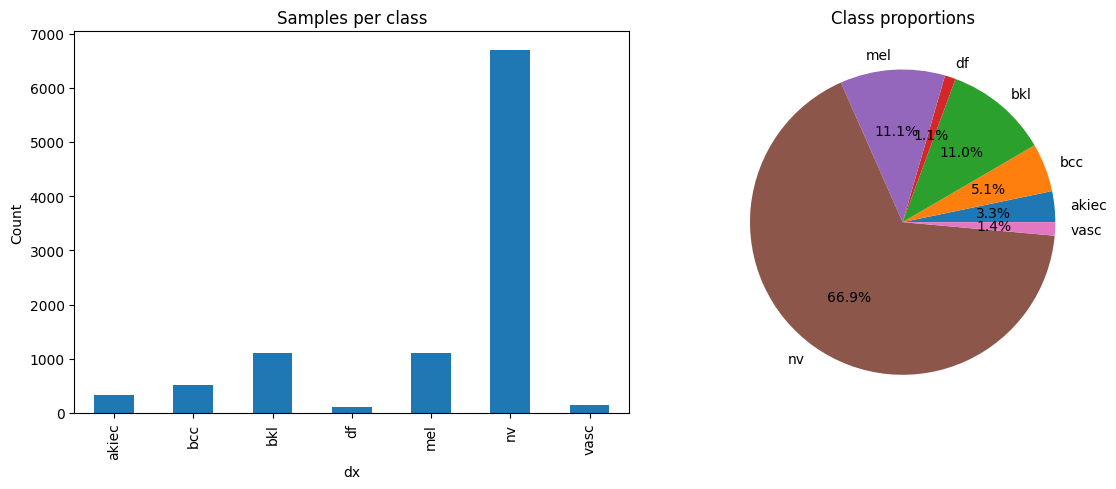

In [25]:
def showdiagramdata():
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    class_counts.plot(kind='bar', ax=axes[0])
    axes[0].set_title('Samples per class')
    axes[0].set_ylabel('Count')

    class_counts.plot(kind='pie', ax=axes[1], autopct='%1.1f%%')
    axes[1].set_ylabel('')
    axes[1].set_title('Class proportions')

    plt.tight_layout()
    plt.show()
    
showdiagramdata()

&nbsp;&nbsp;&nbsp;&nbsp;Заметим, что данные распределены крайне неравномерно, больше элементов, который представляют собой доброкачественные
опухоли. Общее количество изображений < 10.000, поэтому необходимо расширить датасет, добавив немного изображений редких классов, чтобы модель их лучше различала. Для этого применим аугментации к некоторым изображениям (отразим, повернем, сдвинем, увеличим яркость). <br> &nbsp;&nbsp;&nbsp;&nbsp;
Таким образом мы сохраним "качественное распределение" (если в начальном датасете выполнялось, что n > m, где n - количество элементов одно гласса, m - другого, то в редактированном датасете также будет выполнятся это неравенство для любых классов), а также этим методом мы сымитируем различные условия съемки. 

### Расчёт количества аугментаций

После анализа распределения классов было выявлено существенное преобладание класса NV и недостаток изображений для классов DF, VASC, AKIEC и BCC. Такая ситуация может привести к тому, что модель будет ориентироваться преимущественно на наиболее представленные категории и хуже распознавать редкие заболевания.

Для частичной компенсации дисбаланса используется аугментация данных. В качестве целевого значения выбрано 2000 изображений на класс. Для каждого класса вычисляется количество дополнительных изображений, необходимых для достижения данного порога. Новые образцы генерируются с помощью случайных преобразований исходных изображений (повороты, отражения, изменение яркости и контрастности).

Такой подход позволяет увеличить разнообразие обучающей выборки, улучшить обобщающую способность модели и одновременно сохранить исходное соотношение между классами без чрезмерного дублирования данных.

In [26]:
target_threshold = 2000
class_counts = df['dx'].value_counts()
augment_counts = {cls: max(0, target_threshold - count) for cls, count in class_counts.items()}

### Аугментация и сохранение на диск

In [27]:
AUG_DIR = Path('data/augmented')
AUG_DIR.mkdir(exist_ok=True)

strong_tf = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(0.4, 0.4, 0.4, 0.1),
    transforms.ToTensor(),
])

img_dirs = [Path('data/HAM10000_images_part_1'), Path('data/HAM10000_images_part_2')]
img_map = {p.stem: p for d in img_dirs for p in d.glob('*.jpg')}

new_rows = []
for cls, count in augment_counts.items():
    if count <= 0:
        continue
    cls_mask = df['dx'] == cls
    cls_indices = df[cls_mask].index.tolist()
    
    for _ in range(count):
        src_idx = np.random.choice(cls_indices)
        row = df.iloc[src_idx]
        src_path = img_map.get(row['image_id'])
        if not src_path or not src_path.exists():
            continue
        
        img = Image.open(src_path).convert('RGB')
        aug_tensor = strong_tf(img)
        
        new_id = f"aug_{row['image_id']}_{np.random.randint(10000)}"
        transforms.ToPILImage()(aug_tensor).save(AUG_DIR / f"{new_id}.jpg")
        
        new_row = row.copy()
        new_row['image_id'] = new_id
        new_rows.append(new_row)

if new_rows:
    df = pd.concat([df, pd.DataFrame(new_rows)], ignore_index=True)
    img_map.update({p.stem: p for p in AUG_DIR.glob('*.jpg')})

class_counts = df['dx'].value_counts()

### Математика штрафования

Несмотря на применение аугментаций, распределение классов остается несбалансированным. В таких условиях стандартная функция потерь будет сильнее учитывать ошибки на многочисленных классах и практически игнорировать редкие категории.

Для решения этой проблемы каждому классу назначается индивидуальный вес, обратно пропорциональный числу его представителей в обучающей выборке:

W_k = N / (K * n_k)
где N — общее число изображений, K — количество классов, n_k — число объектов класса k.

При таком подходе ошибки на редких классах получают больший штраф, чем ошибки на распространённых. Это заставляет модель уделять больше внимания недостаточно представленным заболеваниям и способствует росту метрики Macro F1, которая является основной метрикой качества в данной задаче.

In [28]:
classes = df['dx'].unique()
class_to_idx = {cls: idx for idx, cls in enumerate(classes)}

total = len(df)
K = len(classes)
weights = {cls: total / (K * count) for cls, count in class_counts.items()}
weight_tensor = torch.tensor([weights[cls] for cls in classes])

In [29]:
lesion_info = df.groupby('lesion_id')['dx'].first().reset_index()
lesion_info = lesion_info.sample(frac=1, random_state=42).reset_index(drop=True)

split_idx = int(len(lesion_info) * 0.8)
train_lesions = lesion_info.iloc[:split_idx]['lesion_id']
val_lesions = lesion_info.iloc[split_idx:]['lesion_id']

train_df = df[df['lesion_id'].isin(train_lesions)].reset_index(drop=True)
val_df = df[df['lesion_id'].isin(val_lesions)].reset_index(drop=True)

train_df['label'] = train_df['dx'].map(class_to_idx)
val_df['label'] = val_df['dx'].map(class_to_idx)

### Dataset и DataLoader

In [32]:
train_tf = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])


criterion = nn.CrossEntropyLoss(weight=weight_tensor)

In [33]:
class SkinDataset(Dataset):
    def __init__(self, dataframe, img_map, transform=None):
        self.df = dataframe
        self.img_map = img_map
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        path = self.img_map.get(row['image_id'])
        img = Image.open(path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, torch.tensor(row['label'], dtype=torch.long)

train_ds = SkinDataset(train_df, img_map, transform=train_tf)
val_ds = SkinDataset(val_df, img_map, transform=val_tf)   
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=0)



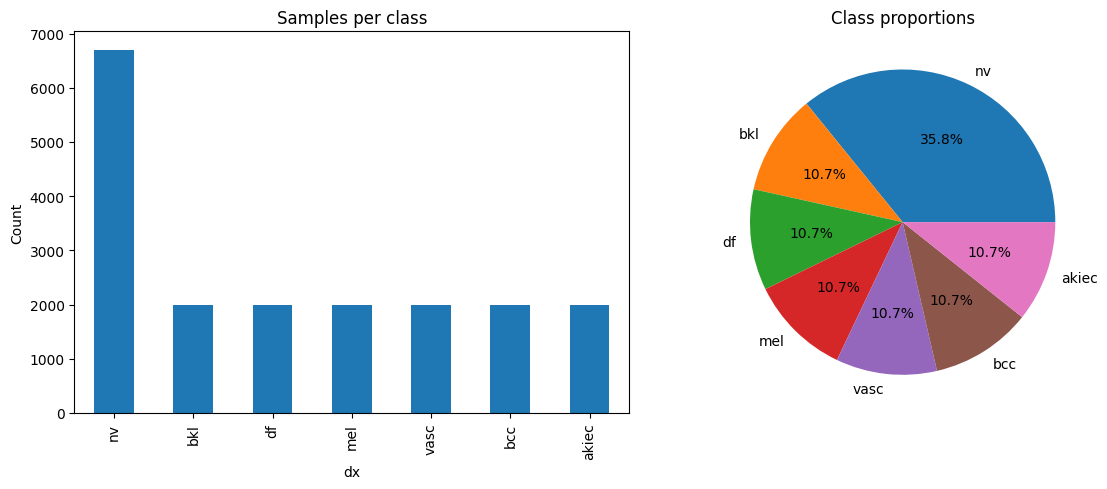

In [34]:
showdiagramdata()

## Модель и обучение


In [35]:
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: mps


In [ ]:
class SkinCNN(nn.Module):
    def __init__(self, num_classes=7):
        super(SkinCNN, self).__init__()
        
        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            
            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            
            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            
            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
        )
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 14 * 14, 512), # 14x14 comes from 224 input / 16 pooling
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [37]:
model = SkinCNN(num_classes=7).to(device)
criterion = nn.CrossEntropyLoss(weight=weight_tensor.to(device))
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

In [38]:
def plot_live(history):
    clear_output(wait=True)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    ax1.plot(history['train_loss'], label='Train')
    ax1.plot(history['val_loss'], label='Val')
    ax1.set_title('Loss')
    ax1.set_xlabel('Epoch')
    ax1.legend()
    ax1.grid(True)
    
    ax2.plot(history['val_f1'], color='orange')
    ax2.set_title('Macro F1 Score (Val)')
    ax2.set_xlabel('Epoch')
    ax2.set_ylim([0, 1])
    ax2.grid(True)
    
    plt.tight_layout()
    plt.show()

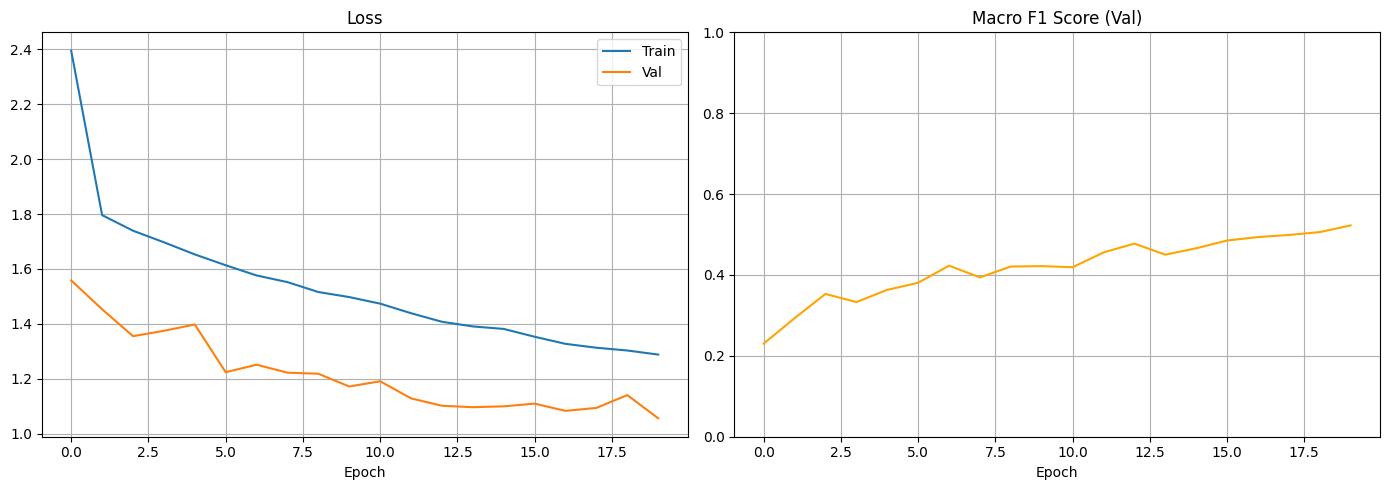

Epoch 20/20 | LR: 1.00e-03
Train Loss: 1.2879 | Val Loss: 1.0555 | Val F1: 0.5225


In [ ]:
model = SkinCNN(num_classes=7).to(device)
criterion = nn.CrossEntropyLoss(weight=weight_tensor.to(device))
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

EPOCHS = 20
history = {'train_loss': [], 'val_loss': [], 'val_f1': []}

for epoch in range(EPOCHS):  ## надо заменить на learn(), но перезапускать всю ячейку очень долго, т.к обучение длится около дву часов на m4
    # Train
    model.train()
    running_loss = 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    
    # Validate
    model.eval()
    val_loss = 0
    val_preds, val_labels = [], []
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            val_preds.extend(outputs.argmax(1).cpu().numpy())
            val_labels.extend(labels.cpu().numpy())
    
    # Metrics
    train_loss = running_loss / len(train_loader)
    val_loss_avg = val_loss / len(val_loader)
    f1 = f1_score(val_labels, val_preds, average='macro')
    
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss_avg)
    history['val_f1'].append(f1)
    
    scheduler.step(val_loss_avg)
    
    # Live update
    plot_live(history)
    print(f"Epoch {epoch+1}/{EPOCHS} | LR: {optimizer.param_groups[0]['lr']:.2e}")
    print(f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss_avg:.4f} | Val F1: {f1:.4f}")

### Анализ результатов


Проблемы текущей модели: <br>
Macro F1 = 0.52 — низкое качество, модель плохо различает редкие классы <br>
36 минут на эпоху — неприемлемо медленно для экспериментов <br>
Val Loss < Train Loss — модель недообучается (underfitting), а не переобучается <br>

<br><br>

Причины:<br>
Linear(256*14*14, 512) создает 25 млн параметров — слишком много, медленно сходится <br>
Обычный Adam без затухания LR застревает в локальных минимумах<br>
num_workers=0 грузит данные последовательно<br>

In [ ]:
import torch.nn.functional as F

class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )
    
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        out = F.relu(out)
        return out
    
class ImprovedSkinCNN(nn.Module): ## другая заготовка (не успел протестировтаь)
    def __init__(self, num_classes=7):
        super().__init__()
        
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(32)
        
        # Residual blocks
        self.layer1 = self._make_layer(32, 64, 2)
        self.layer2 = self._make_layer(64, 128, 2)
        self.layer3 = self._make_layer(128, 256, 2)
        self.layer4 = self._make_layer(256, 512, 2)
        
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(512, num_classes)
        
    def _make_layer(self, in_channels, out_channels, stride):
        return nn.Sequential(
            ResidualBlock(in_channels, out_channels, stride),
            ResidualBlock(out_channels, out_channels, 1)
        )
    
    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.gap(x)
        x = self.dropout(x)
        x = self.fc(x.view(x.size(0), -1))
        return x


In [50]:
# 1. Focal Loss для несбалансированных классов
class FocalLoss(nn.Module):
    def __init__(self, alpha=1, gamma=2):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
    
    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = self.alpha * (1-pt)**self.gamma * ce_loss
        return focal_loss.mean()

# 2. Cosine Annealing с warmup
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20, eta_min=1e-6)

# 3. Label smoothing
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

# 4. Gradient clipping
torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

tensor(0.0253, device='mps:0')

In [51]:
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

In [55]:
def learn(model, criterion, optimizer, scheduler):
    EPOCHS = 20
    history = {'train_loss': [], 'val_loss': [], 'val_f1': []}

    for epoch in range(EPOCHS):
        # Train
        model.train()
        running_loss = 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        
        # Validate
        model.eval()
        val_loss = 0
        val_preds, val_labels = [], []
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item()
                val_preds.extend(outputs.argmax(1).cpu().numpy())
                val_labels.extend(labels.cpu().numpy())
        
        # Metrics
        train_loss = running_loss / len(train_loader)
        val_loss_avg = val_loss / len(val_loader)
        f1 = f1_score(val_labels, val_preds, average='macro')
        
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss_avg)
        history['val_f1'].append(f1)
        
        scheduler.step(val_loss_avg)
        
        # Live update
        plot_live(history)
        print(f"Epoch {epoch+1}/{EPOCHS} | LR: {optimizer.param_groups[0]['lr']:.2e}")
        print(f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss_avg:.4f} | Val F1: {f1:.4f}")


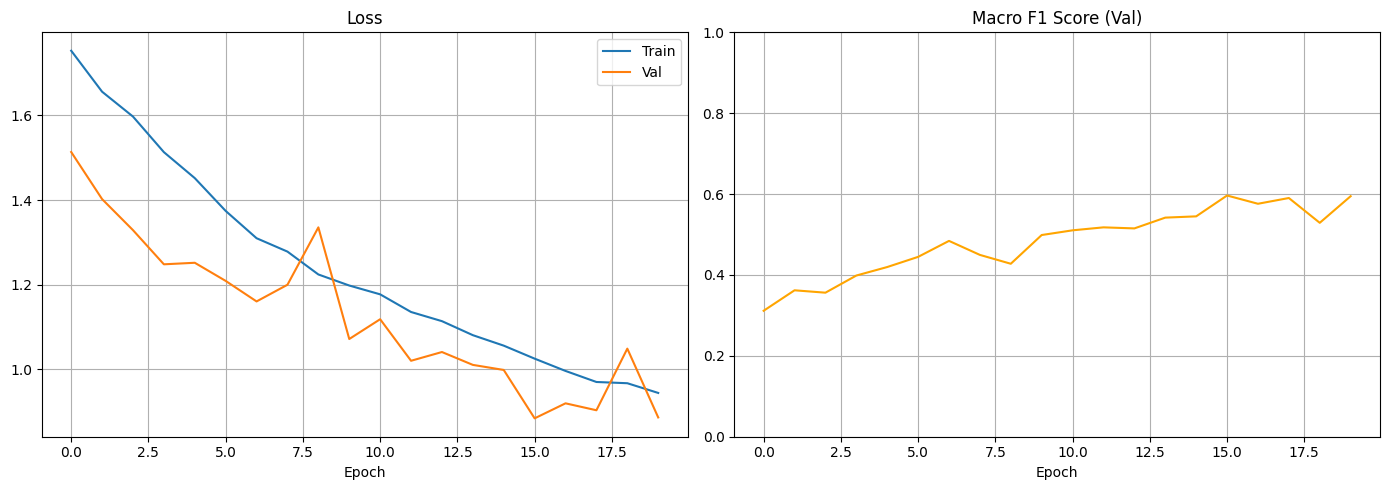

Epoch 20/20 | LR: 9.95e-04
Train Loss: 0.9442 | Val Loss: 0.8863 | Val F1: 0.5948


: 

In [ ]:
class ResBlock(nn.Module):
    def __init__(self, in_c, out_c, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_c, out_c, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_c)
        
        self.skip = nn.Sequential()
        if stride != 1 or in_c != out_c:
            self.skip = nn.Sequential(
                nn.Conv2d(in_c, out_c, 1, stride, bias=False),
                nn.BatchNorm2d(out_c)
            )

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return torch.relu(out + self.skip(x))

class ProSkinCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, 3, 1, 1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            
            ResBlock(32, 64, 2),
            ResBlock(64, 128, 2),
            ResBlock(128, 256, 2),
            ResBlock(256, 512, 2),
            
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.2),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        return self.net(x)

model = ProSkinCNN(num_classes=7).to('mps')
criterion = nn.CrossEntropyLoss(weight=weight_tensor.to(device))
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)
learn(model, criterion, optimizer, scheduler)

# Сравнение и анализ результатов

После 20 эпох обучения модель ProSkinCNN достигла значения Macro F1 = 0.5948 при значениях Train Loss = 0.9442 и Val Loss = 0.8863.

Графики обучения демонстрируют устойчивое снижение функции потерь как на обучающей, так и на валидационной выборке. Отсутствие расхождения между кривыми позволяет сделать вывод об отсутствии выраженного переобучения. Более низкое значение Val Loss по сравнению с Train Loss может объясняться использованием аугментаций и взвешенной функции потерь на этапе обучения, что делает обучающую задачу более сложной.

По сравнению с базовой архитектурой SkinCNN качество классификации увеличилось с Macro F1 = 0.5225 до Macro F1 = 0.5948, что соответствует приросту примерно на 14 %. Улучшение связано с использованием остаточных соединений (Residual Connections), которые облегчают распространение градиента в глубоких сетях, а также с заменой крупного полносвязного слоя на Global Average Pooling, что позволило существенно сократить число параметров модели.

Несмотря на достигнутый результат, качество классификации остаётся ограниченным из-за небольшого объёма датасета и сильного дисбаланса классов. Дальнейшее повышение точности может быть достигнуто за счёт использования предобученных архитектур (ResNet, EfficientNet), более сложных методов аугментации данных и увеличения объёма обучающей выборки.